In [50]:
import pandas as pd

df_train = pd.read_csv("train.csv")
df_test = pd.read_csv("test.csv")

df_train.head()

,image_path,label
0,images/ecg_004753.png,0
1,images/ecg_000291.png,1
2,images/ecg_001008.png,0
3,images/ecg_003000.png,1
4,images/ecg_003964.png,1


310
308


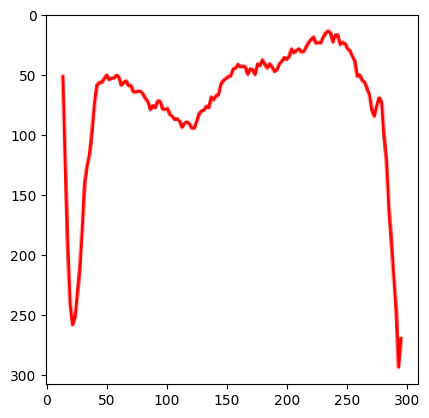

In [51]:
from PIL import Image
import matplotlib.pyplot as plt

img = Image.open("images/ecg_001008.png")
print(img.size[0])
print(img.size[1])
plt.imshow(img)

In [62]:
import torch

batch_size = 32
epochs = 5
learning_rate = 0.0001

device = torch.device("cuda")
device

device(type='cuda')

In [63]:
from torch.utils.data import Dataset, DataLoader
import torchvision.transforms as T

train_transform = T.Compose([
    T.ToTensor()
])

valid_transform = T.Compose([
    T.ToTensor()
])

class MyDataset(Dataset):
    def __init__(self, df, transform):
        self.df = df
        self.transform = transform
    def __len__(self):
        return len(self.df)
    def __getitem__(self, idx):
        path = self.df.image_path.iloc[idx]
        img = Image.open(path).convert("RGB")
        img = self.transform(img)
        label = torch.tensor(self.df.label.iloc[idx], dtype=torch.float64).view(1)
        return img, label

from sklearn.model_selection import train_test_split
df_1, df_2 = train_test_split(df_train, test_size=0.1, random_state=42)

train_dataset = MyDataset(df_1, train_transform)
train_loader = DataLoader(train_dataset, batch_size=batch_size)

valid_dataset = MyDataset(df_2, valid_transform)
valid_loader = DataLoader(valid_dataset, batch_size=batch_size)

In [64]:
train_dataset[0][0][0][0][0]

tensor(1.)

In [65]:
import torch.nn as nn

class CNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv2d(3, 16, 3),
            nn.ReLU(),
            nn.MaxPool2d(2, 2),
            nn.Conv2d(16, 32, 3),
            nn.ReLU(),
            nn.MaxPool2d(2, 2),
            nn.Conv2d(32, 64, 3),
            nn.ReLU(),
            nn.MaxPool2d(2, 2),

            nn.Flatten(),
            nn.LazyLinear(64),
            nn.ReLU(),
            nn.Linear(64, 32),
            nn.ReLU(),
            nn.Linear(32, 1)
        )
    def forward(self, X):
        X = self.net(X)
        return X

model = CNN().to(device)
criterion = nn.BCEWithLogitsLoss()
optimizer = torch.optim.AdamW(model.parameters(), lr=learning_rate)

model

CNN(
  (net): Sequential(
    (0): Conv2d(3, 16, kernel_size=(3, 3), stride=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (6): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1))
    (7): ReLU()
    (8): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (9): Flatten(start_dim=1, end_dim=-1)
    (10): LazyLinear(in_features=0, out_features=64, bias=True)
    (11): ReLU()
    (12): Linear(in_features=64, out_features=32, bias=True)
    (13): ReLU()
    (14): Linear(in_features=32, out_features=1, bias=True)
  )
)

In [66]:
def train(model, criterion, train_loader, optimizer, epoch):
    model.train()
    total_loss = 0
    for inputs, labels in train_loader:
        inputs, labels = inputs.to(device), labels.to(device)
        loss = criterion(model(inputs), labels)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        total_loss += loss.item()
    print(f"Epoch {epoch}")
    print(f"Training Loss {total_loss/len(train_loader)}")
def test(model, criterion, test_loader):
    model.eval()
    total_loss = 0
    with torch.no_grad():
        for inputs, labels in test_loader:
            inputs, labels = inputs.to(device), labels.to(device)
            loss = criterion(model(inputs), labels)
            total_loss += loss.item()
    print(f"Validation Loss {total_loss/len(test_loader)}")

In [67]:
for epoch in range(1, epochs+1):
    train(model, criterion, train_loader, optimizer, epoch)
    test(model, criterion, valid_loader)

Epoch 1
Training Loss 0.31604878718478685
Validation Loss 0.07889141022315016
Epoch 2
Training Loss 0.07342142283146662
Validation Loss 0.05708978907121211
Epoch 3
Training Loss 0.04678226312995049
Validation Loss 0.03849290139693879
Epoch 4
Training Loss 0.035348964993983344
Validation Loss 0.025440699981817697
Epoch 5
Training Loss 0.02812691425405009
Validation Loss 0.021985891655206685


In [68]:
final_transform = T.Compose([
    T.ToTensor()
])

class FinalDataset(Dataset):
    def __init__(self, df, transform):
        self.df = df
        self.transform = transform
    def __len__(self):
        return len(self.df)
    def __getitem__(self, idx):
        path = self.df.image_path.iloc[idx]
        img = Image.open(path).convert("RGB")
        img = self.transform(img)
        return img

final_dataset = FinalDataset(df_test, final_transform)
final_loader = DataLoader(final_dataset, batch_size=batch_size)

In [69]:
model.eval()
preds = []

with torch.no_grad():
    for inputs in final_loader:
        inputs = inputs.to(device)
        outputs = torch.sigmoid(model(inputs)).cpu()
        preds.append(outputs)

preds = torch.cat(preds, dim=0).numpy().flatten()
preds = (preds > 0.5).astype(int)
preds[:10]

array([1, 1, 0, 0, 1, 1, 0, 1, 0, 1])

In [70]:
df_preds = pd.DataFrame({
    "image_path": df_test.image_path,
    "label": preds
})

df_preds

,image_path,label
0,images/ecg_004311.png,1
1,images/ecg_001394.png,1
2,images/ecg_000341.png,0
3,images/ecg_000241.png,0
4,images/ecg_001789.png,1
...,...,...
995,images/ecg_003137.png,0
996,images/ecg_004020.png,0
997,images/ecg_000585.png,1
998,images/ecg_004507.png,1


In [71]:
df_preds.to_csv("submission.csv", index=False)